In [ ]:
!pip install yfinance

In [ ]:
!pip install statsmodels

In [ ]:
import pandas as pd
import numpy as np
import sklearn as sk
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.layers import GRU
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
from statsmodels.tsa.stattools import adfuller
from scipy.stats import boxcox
from scipy.special import inv_boxcox

In [ ]:
# Define the tickers and date range
ticker_sgd_usd = 'SGDUSD=X'
ticker_idr_usd = 'IDRUSD=X'
start_date = '2013-10-23'
end_date = '2024-10-22'

# Fetch historical data for SGD to USD
data_sgd_usd = yf.download(ticker_sgd_usd, start=start_date, end=end_date)

# Fetch historical data for IDR to USD
data_idr_usd = yf.download(ticker_idr_usd, start=start_date, end=end_date)

# Extract only 'Adj Close' and 'Date' columns for both datasets
data_sgd_usd = data_sgd_usd[['Adj Close']].reset_index()
data_idr_usd = data_idr_usd[['Adj Close']].reset_index()

# Rename columns for clarity
data_sgd_usd.columns = ['Date', 'Adj Close']
data_idr_usd.columns = ['Date', 'Adj Close']

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


In [ ]:
# Check for missing values
print("Missing values in SGD data:")
print(data_sgd_usd.isnull().sum())

print("\nMissing values in IDR data:")
print(data_idr_usd.isnull().sum())

Missing values in SGD data:
Date         0
Adj Close    0
dtype: int64

Missing values in IDR data:
Date         0
Adj Close    0
dtype: int64


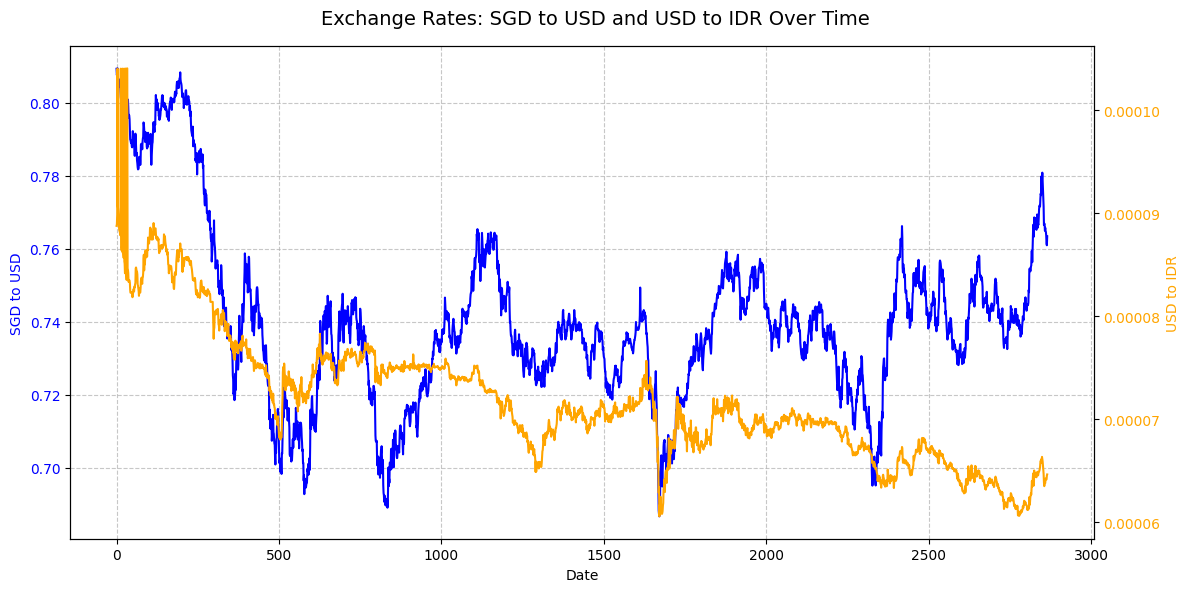

In [ ]:
# Plot both SGD to USD and USD to IDR exchange rates on the same figure
fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot SGD to USD on the left y-axis
ax1.plot(data_sgd_usd.index, data_sgd_usd['Adj Close'], label='SGD to USD', color='blue')
ax1.set_xlabel('Date')
ax1.set_ylabel('SGD to USD', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')
ax1.grid(True, which='major', linestyle='--', alpha=0.7)

# Create a second y-axis for USD to IDR
ax2 = ax1.twinx()
ax2.plot(data_idr_usd.index, data_idr_usd['Adj Close'], label='USD to IDR', color='orange')
ax2.set_ylabel('USD to IDR', color='orange')
ax2.tick_params(axis='y', labelcolor='orange')

# Add a title and legend
fig.suptitle('Exchange Rates: SGD to USD and USD to IDR Over Time', fontsize=14)
fig.tight_layout()
plt.show()

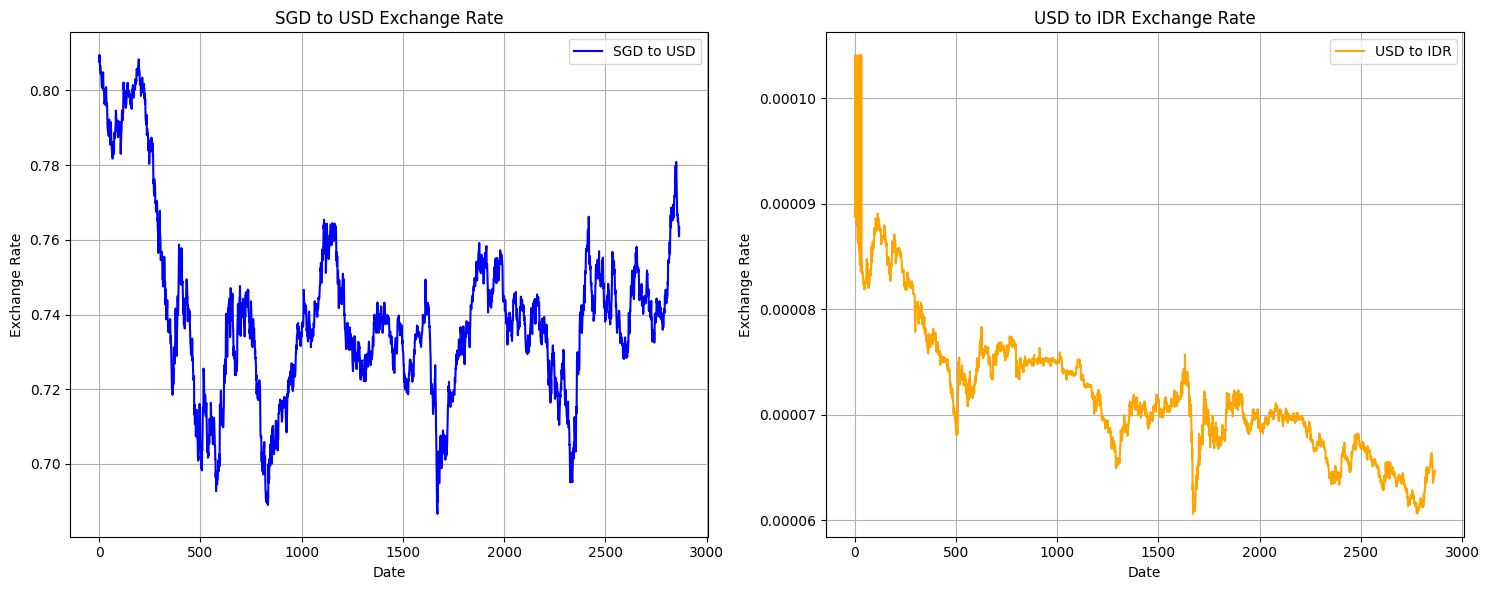

In [ ]:
import matplotlib.pyplot as plt

# Create a figure with two subplots side by side
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True)

# Plot SGD to USD on the left subplot
axes[0].plot(data_sgd_usd.index, data_sgd_usd['Adj Close'], label='SGD to USD', color='blue')
axes[0].set_title('SGD to USD Exchange Rate')
axes[0].set_xlabel('Date')
axes[0].set_ylabel('Exchange Rate')
axes[0].grid(True)
axes[0].legend()

# Plot USD to IDR on the right subplot
axes[1].plot(data_idr_usd.index, data_idr_usd['Adj Close'], label='USD to IDR', color='orange')
axes[1].set_title('USD to IDR Exchange Rate')
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Exchange Rate')
axes[1].grid(True)
axes[1].legend()

# Adjust layout
plt.tight_layout()
plt.show()

In [ ]:
# Prepare data for SGD and IDR
def create_sequences(data, seq_length):
    xs = []
    ys = []
    for i in range(len(data)-seq_length-1):
        x = data[i:(i+seq_length)]
        y = data[i+seq_length]
        xs.append(x)
        ys.append(y)
    return np.array(xs), np.array(ys)

seq_length = 120  # Adjust as needed

In [ ]:
# Prepare SGD data
scaler_sgd = StandardScaler()
data_sgd_scaled = scaler_sgd.fit_transform(data_sgd_usd['Adj Close'].values.reshape(-1, 1))

X_sgd, y_sgd = create_sequences(data_sgd_scaled, seq_length)
X_sgd = X_sgd.reshape(X_sgd.shape[0], X_sgd.shape[1], 1)

split_sgd = int(0.7 * len(X_sgd))
X_sgd_train, X_sgd_test = X_sgd[:split_sgd], X_sgd[split_sgd:]
y_sgd_train, y_sgd_test = y_sgd[:split_sgd], y_sgd[split_sgd:]

# Prepare IDR data (no differencing)
scaler_idr = StandardScaler()
data_idr_scaled = scaler_idr.fit_transform(data_idr_usd['Adj Close'].values.reshape(-1, 1))

X_idr, y_idr = create_sequences(data_idr_scaled, seq_length)
X_idr = X_idr.reshape(X_idr.shape[0], X_idr.shape[1], 1)

split_idr = int(0.7 * len(X_idr))
X_idr_train, X_idr_test = X_idr[:split_idr], X_idr[split_idr:]
y_idr_train, y_idr_test = y_idr[:split_idr], y_idr[split_idr:]

In [ ]:
# Early stopping configuration
early_stopping = EarlyStopping(monitor='loss',  # Monitor validation loss
                               patience=4,         # Number of epochs with no improvement before stopping
                               restore_best_weights=True,  # Restore model weights from the best epoch
                               verbose=1)           # Display messages when stopping

In [ ]:
# Create and train LSTM model for SGD
model_sgd = Sequential()
model_sgd.add(LSTM(units=50, return_sequences=True, input_shape=(X_sgd.shape[1], 1), dropout=0.2, recurrent_dropout=0.2))
model_sgd.add(LSTM(units=50))
model_sgd.add(Dense(1))
model_sgd.compile(loss='mean_squared_error', optimizer='adam')
model_sgd.fit(X_sgd_train, y_sgd_train, epochs=100, batch_size=32, callbacks=[early_stopping])

/usr/local/lib/python3.10/dist-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 22s 237ms/step - loss: 0.4063
Epoch 2/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 13s 109ms/step - loss: 0.1834
Epoch 3/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 10s 109ms/step - loss: 0.2282
Epoch 4/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 8s 134ms/step - loss: 0.2565
Epoch 5/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 7s 110ms/step - loss: 0.2324
Epoch 6/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 8s 137ms/step - loss: 0.2069
Epoch 6: early stopping
Restoring model weights from the end of the best epoch: 2.


In [ ]:
# Create and train LSTM model for IDR
model_idr = Sequential()
model_idr.add(LSTM(units=50, return_sequences=True, input_shape=(X_idr.shape[1], 1), dropout=0.2, recurrent_dropout=0.2))
model_idr.add(LSTM(units=50))
model_idr.add(Dense(1))
model_idr.compile(loss='mean_squared_error', optimizer='adam')
model_idr.fit(X_idr_train, y_idr_train, epochs=100, batch_size=32, callbacks=[early_stopping])

Epoch 1/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 11s 127ms/step - loss: 0.2153
Epoch 2/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 7s 118ms/step - loss: 0.1263
Epoch 3/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 11s 138ms/step - loss: 0.1115
Epoch 4/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 9s 143ms/step - loss: 0.1270
Epoch 5/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 9s 121ms/step - loss: 0.1553
Epoch 6/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 8s 137ms/step - loss: 0.1252
Epoch 7/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 9s 111ms/step - loss: 0.1307
Epoch 7: early stopping
Restoring model weights from the end of the best epoch: 3.


In [ ]:
# Make predictions
y_pred_sgd = model_sgd.predict(X_sgd_test)
y_pred_idr = model_idr.predict(X_idr_test)

# Inverse transform the predictions
y_pred_sgd = scaler_sgd.inverse_transform(y_pred_sgd)
y_pred_idr = scaler_idr.inverse_transform(y_pred_idr)
y_sgd_test = scaler_sgd.inverse_transform(y_sgd_test)
y_idr_test = scaler_idr.inverse_transform(y_idr_test)

26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step
26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step


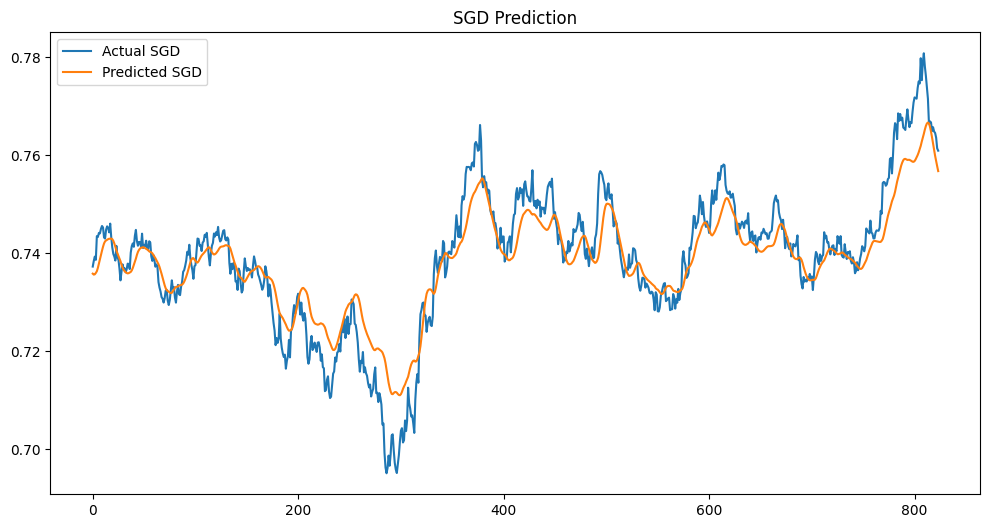

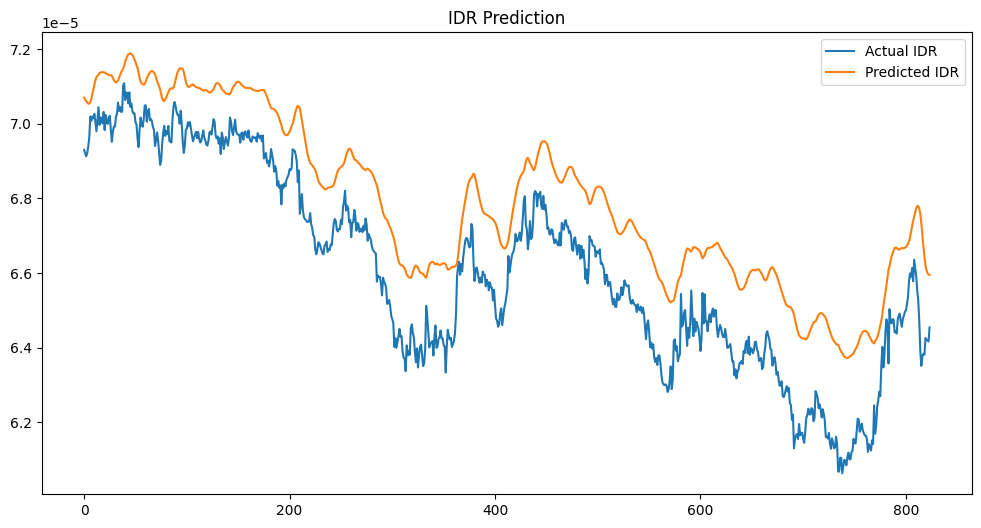

In [ ]:
# Plotting SGD Test Prediction
plt.figure(figsize=(12, 6))
plt.plot(y_sgd_test, label='Actual SGD')
plt.plot(y_pred_sgd, label='Predicted SGD')
plt.legend()
plt.title('SGD Prediction')
plt.show()

# Plotting IDR Test Prediction
plt.figure(figsize=(12, 6))
plt.plot(y_idr_test, label='Actual IDR')
plt.plot(y_pred_idr, label='Predicted IDR')
plt.legend()
plt.title('IDR Prediction')
plt.show()

In [ ]:
# LSTM-GRU Model for SGD
model_sgd_gru = Sequential()
model_sgd_gru.add(LSTM(units=50, return_sequences=True, input_shape=(X_sgd.shape[1], 1)))  # LSTM layer with return_sequences=True
model_sgd_gru.add(GRU(units=50))  # GRU layer
model_sgd_gru.add(Dropout(0.2))
model_sgd_gru.add(Dense(1))  # Output layer
model_sgd_gru.compile(loss='mean_squared_error', optimizer='adam')
model_sgd_gru.fit(X_sgd_train, y_sgd_train, epochs=100, batch_size=32,
                  callbacks=[early_stopping])

Epoch 1/100


/usr/local/lib/python3.10/dist-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


61/61 ━━━━━━━━━━━━━━━━━━━━ 12s 150ms/step - loss: 0.3519
Epoch 2/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 9s 146ms/step - loss: 0.0373
Epoch 3/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 8s 128ms/step - loss: 0.0349
Epoch 4/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 12s 154ms/step - loss: 0.0290
Epoch 5/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 10s 154ms/step - loss: 0.0288
Epoch 6/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 9s 128ms/step - loss: 0.0269
Epoch 7/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 11s 142ms/step - loss: 0.0241
Epoch 8/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 11s 157ms/step - loss: 0.0239
Epoch 9/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 8s 138ms/step - loss: 0.0206
Epoch 10/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 10s 128ms/step - loss: 0.0234
Epoch 11/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 11s 139ms/step - loss: 0.0206
Epoch 12/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 9s 149ms/step - loss: 0.0230
Epoch 13/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 9s 125ms/step - loss: 0.0193
Epoch 14/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 9s 154ms/step - loss: 0.0180
Epoch 15/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 10s 147m

In [ ]:
# LSTM-GRU Model for IDR
model_idr_gru = Sequential()
model_idr_gru.add(LSTM(units=50, return_sequences=True, input_shape=(X_idr.shape[1], 1)))  # LSTM layer with return_sequences=True
model_idr_gru.add(GRU(units=50))  # GRU layer
model_idr_gru.add(Dropout(0.2))
model_idr_gru.add(Dense(1))  # Output layer
model_idr_gru.compile(loss='mean_squared_error', optimizer='adam')
model_idr_gru.fit(X_idr_train, y_idr_train, epochs=100, batch_size=32,
                  callbacks=[early_stopping])

Epoch 1/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 13s 150ms/step - loss: 0.1884
Epoch 2/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 10s 150ms/step - loss: 0.0191
Epoch 3/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 10s 154ms/step - loss: 0.0166
Epoch 4/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 9s 149ms/step - loss: 0.0151
Epoch 5/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 9s 151ms/step - loss: 0.0162
Epoch 6/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 9s 125ms/step - loss: 0.0145
Epoch 7/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 11s 132ms/step - loss: 0.0142
Epoch 8/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 12s 155ms/step - loss: 0.0138
Epoch 9/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 10s 152ms/step - loss: 0.0132
Epoch 10/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 9s 131ms/step - loss: 0.0123
Epoch 11/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 11s 144ms/step - loss: 0.0131
Epoch 12/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 11s 154ms/step - loss: 0.0107
Epoch 13/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 14s 219ms/step - loss: 0.0107
Epoch 14/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 16s 146ms/step - loss: 0.0113
Epoch 15/100
61/61 ━━━━━━━━━━━━━━

In [ ]:
# Predictions using LSTM-GRU models
y_pred_sgd_gru = model_sgd_gru.predict(X_sgd_test)
y_pred_idr_gru = model_idr_gru.predict(X_idr_test)

# Inverse transform the predictions
y_pred_sgd_gru = scaler_sgd.inverse_transform(y_pred_sgd_gru)
y_pred_idr_gru = scaler_idr.inverse_transform(y_pred_idr_gru)

26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 66ms/step
26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step


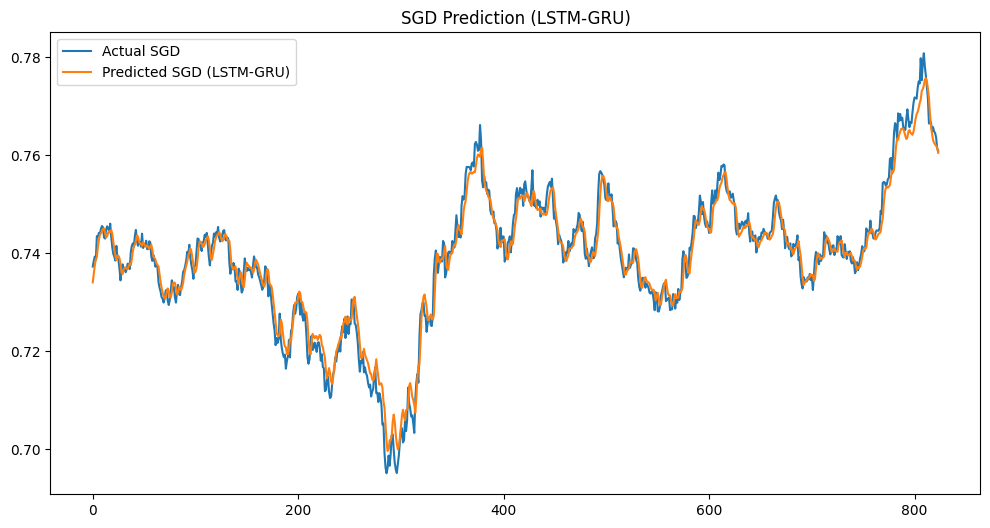

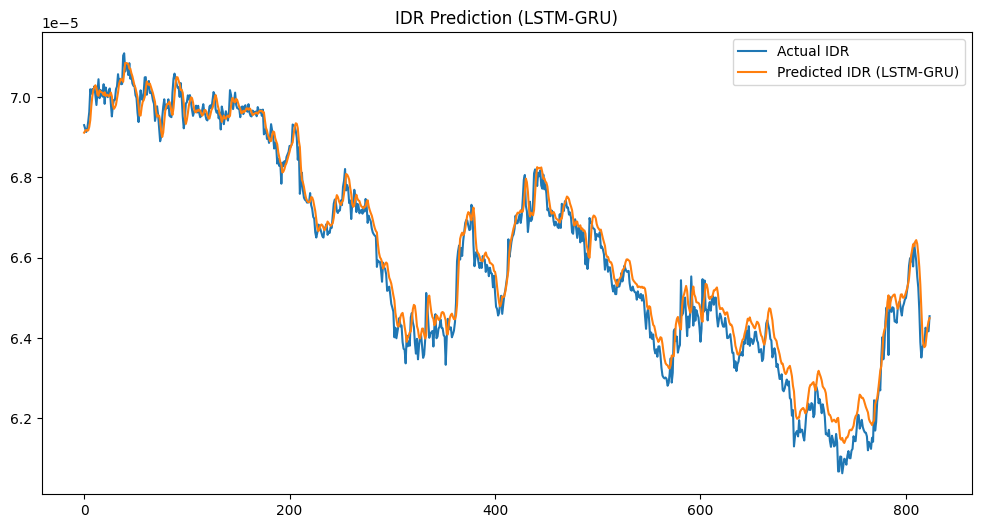

In [ ]:
# Plotting SGD Predictions for LSTM-GRU Models
plt.figure(figsize=(12, 6))
plt.plot(y_sgd_test, label='Actual SGD')
plt.plot(y_pred_sgd_gru, label='Predicted SGD (LSTM-GRU)')
plt.legend()
plt.title('SGD Prediction (LSTM-GRU)')
plt.show()

# Plotting IDR Predictions for LSTM-GRU Models
plt.figure(figsize=(12, 6))
plt.plot(y_idr_test, label='Actual IDR')
plt.plot(y_pred_idr_gru, label='Predicted IDR (LSTM-GRU)')
plt.legend()
plt.title('IDR Prediction (LSTM-GRU)')
plt.show()

In [ ]:
# Calculate RMSE, MSE, and MAE for SGD
rmse_sgd = np.sqrt(mean_squared_error(y_sgd_test, y_pred_sgd))
mape_sgd = mean_absolute_percentage_error(y_sgd_test, y_pred_sgd)
mae_sgd = mean_absolute_error(y_sgd_test, y_pred_sgd)

print(f"SGD - RMSE: {rmse_sgd:.20f}, MAPE: {mape_sgd:.20f}, MAE: {mae_sgd:.20f}")

# Calculate RMSE, MSE, and MAE for IDR
rmse_idr = np.sqrt(mean_squared_error(y_idr_test, y_pred_idr))
mape_idr = mean_absolute_percentage_error(y_idr_test, y_pred_idr)
mae_idr = mean_absolute_error(y_idr_test, y_pred_idr)

print(f"IDR - RMSE: {rmse_idr:.20f}, MAPE: {mape_idr:.20f}, MAE: {mae_idr:.20f}")

# Calculate RMSE, MSE, and MAE for SGD LSTM-GRU
rmse_sgd_gru = np.sqrt(mean_squared_error(y_sgd_test, y_pred_sgd_gru))
mape_sgd_gru = mean_absolute_percentage_error(y_sgd_test, y_pred_sgd_gru)
mae_sgd_gru = mean_absolute_error(y_sgd_test, y_pred_sgd_gru)

print(f"SGD LSTM-GRU - RMSE: {rmse_sgd_gru:.20f}, MAPE: {mape_sgd_gru:.20f}, MAE: {mae_sgd_gru:.20f}")

# Calculate RMSE, MSE, and MAE for IDR LSTM-GRU
rmse_idr_gru = np.sqrt(mean_squared_error(y_idr_test, y_pred_idr_gru))
mape_idr_gru = mean_absolute_percentage_error(y_idr_test, y_pred_idr_gru)
mae_idr_gru = mean_absolute_error(y_idr_test, y_pred_idr_gru)

print(f"IDR LSTM-GRU - RMSE: {rmse_idr_gru:.20f}, MAPE: {mape_idr_gru:.20f}, MAE: {mae_idr_gru:.20f}")

SGD - RMSE: 0.00565019011133436819, MAPE: 0.00576690880663627801, MAE: 0.00425149746311521103
IDR - RMSE: 0.00000189254702438905, MAPE: 0.02757079288394157293, MAE: 0.00000180092681669353
SGD LSTM-GRU - RMSE: 0.00267699851466343588, MAPE: 0.00279553281534574869, MAE: 0.00206118590623429691
IDR LSTM-GRU - RMSE: 0.00000041694736158162, MAPE: 0.00506678791318903102, MAE: 0.00000032971375881105


In [ ]:
# Helper function to make predictions for the next `n` days
def predict_next_year(model, X_data, scaler, n_days=365):
    predictions = []
    current_input = X_data[-1]  # Start from the last available data point (latest in the test set)

    for _ in range(n_days):
        # Predict the next day
        pred = model.predict(current_input.reshape(1, current_input.shape[0], current_input.shape[1]))

        # Append the prediction to the list
        predictions.append(pred[0][0])

        # Update the input sequence by adding the prediction and removing the first element
        current_input = np.append(current_input[1:], pred, axis=0)

    # Inverse transform predictions back to original scale
    predictions = scaler.inverse_transform(np.array(predictions).reshape(-1, 1))
    return predictions

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━

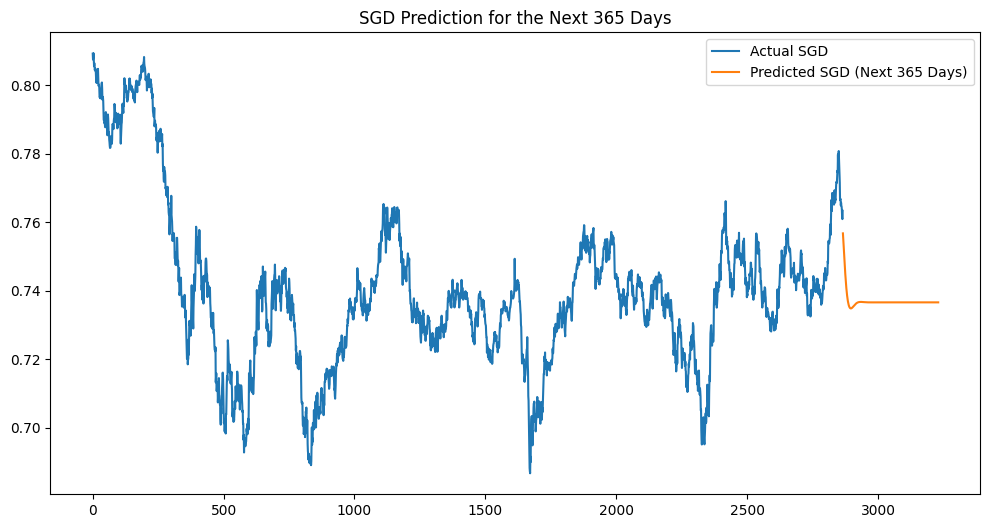

In [ ]:
# SGD LSTM
sgd_predictions_next_year = predict_next_year(model_sgd, X_sgd_test, scaler_sgd, n_days=365)

plt.figure(figsize=(12, 6))
plt.plot(range(len(data_sgd_usd)), scaler_sgd.inverse_transform(data_sgd_scaled), label='Actual SGD')
plt.plot(range(len(data_sgd_usd), len(data_sgd_usd) + 365), sgd_predictions_next_year, label='Predicted SGD (Next 365 Days)')
plt.legend()
plt.title('SGD Prediction for the Next 365 Days')
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━

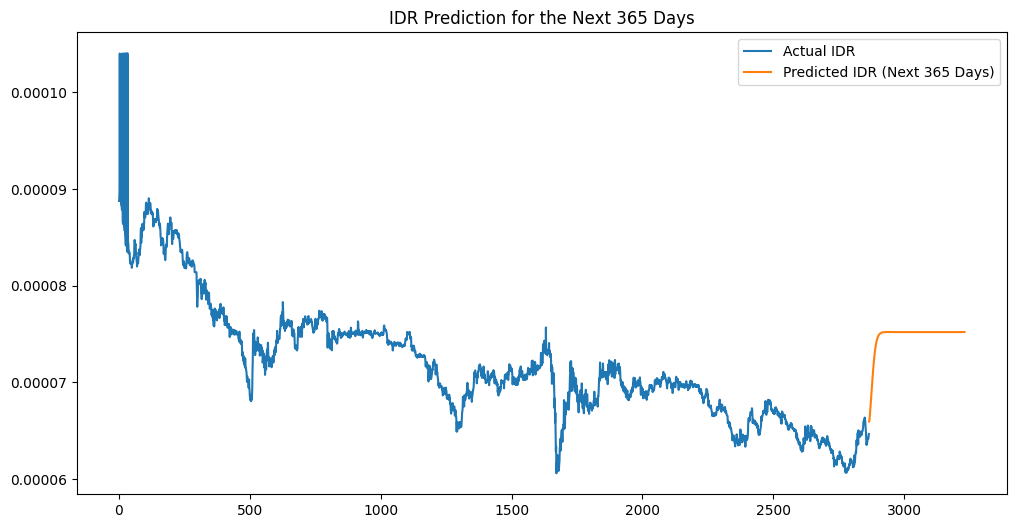

In [ ]:
# IDR LSTM
idr_predictions_next_year = predict_next_year(model_idr, X_idr_test, scaler_idr, n_days=365)

plt.figure(figsize=(12, 6))
plt.plot(range(len(data_idr_usd)), scaler_idr.inverse_transform(data_idr_scaled), label='Actual IDR')
plt.plot(range(len(data_idr_usd), len(data_idr_usd) + 365), idr_predictions_next_year, label='Predicted IDR (Next 365 Days)')
plt.legend()
plt.title('IDR Prediction for the Next 365 Days')
plt.show()

In [ ]:
print("SGD/USD Next Year Prediction:")
print(sgd_predictions_next_year[364][0])

print("\nIDR/USD Next Year Prediction:")
print(idr_predictions_next_year[364][0])

SGD/USD Next Year Prediction:
0.73661184

IDR/USD Next Year Prediction:
7.520303e-05


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━

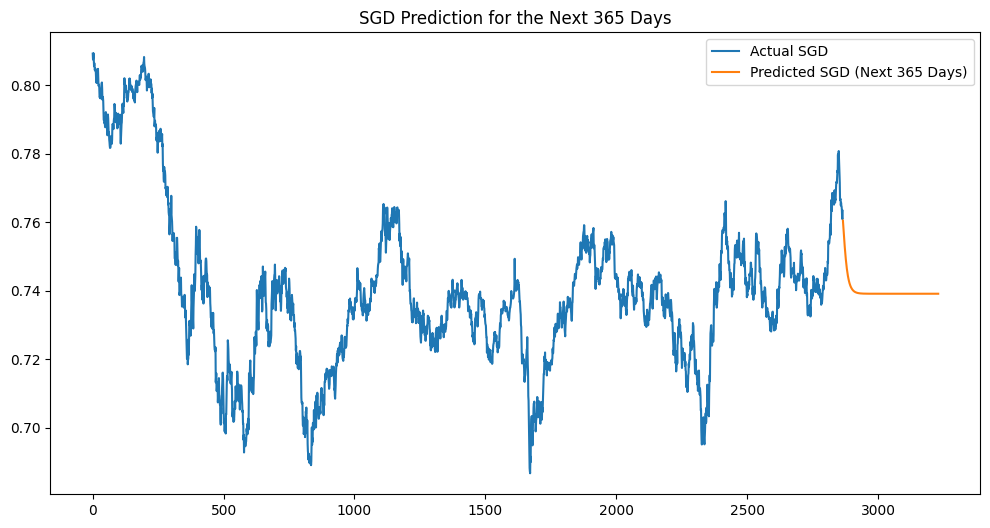

In [ ]:
# SGD LSTM-GRU
sgd_predictions_next_year_gru = predict_next_year(model_sgd_gru, X_sgd_test, scaler_sgd, n_days=365)

plt.figure(figsize=(12, 6))
plt.plot(range(len(data_sgd_usd)), scaler_sgd.inverse_transform(data_sgd_scaled), label='Actual SGD')
plt.plot(range(len(data_sgd_usd), len(data_sgd_usd) + 365), sgd_predictions_next_year_gru, label='Predicted SGD (Next 365 Days)')
plt.legend()
plt.title('SGD Prediction for the Next 365 Days')
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━

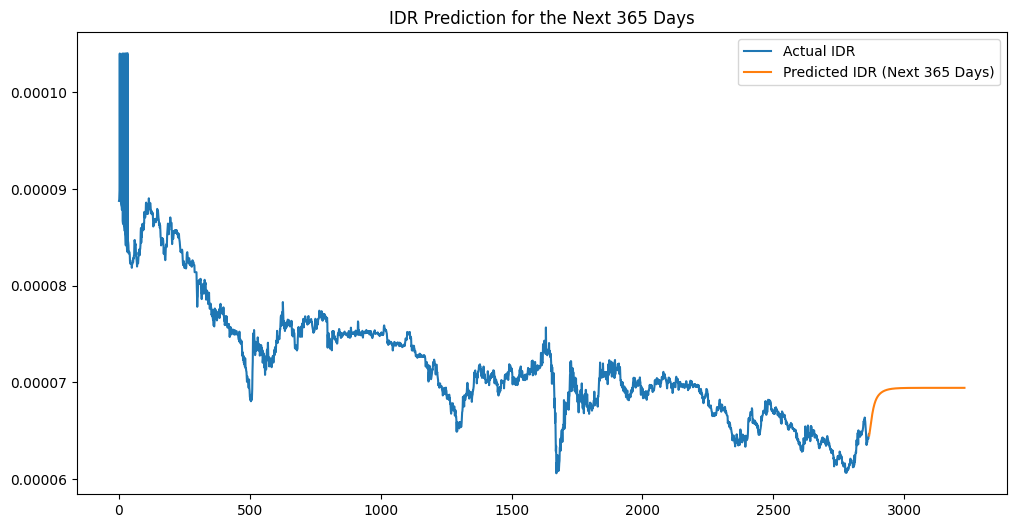

In [ ]:
# IDR LSTM-GRU
idr_predictions_next_year_gru = predict_next_year(model_idr_gru, X_idr_test, scaler_idr, n_days=365)

plt.figure(figsize=(12, 6))
plt.plot(range(len(data_idr_usd)), scaler_idr.inverse_transform(data_idr_scaled), label='Actual IDR')
plt.plot(range(len(data_idr_usd), len(data_idr_usd) + 365), idr_predictions_next_year_gru, label='Predicted IDR (Next 365 Days)')
plt.legend()
plt.title('IDR Prediction for the Next 365 Days')
plt.show()

In [ ]:
print("SGD/USD Next Year Prediction:")
print(sgd_predictions_next_year_gru[364][0])

print("\nIDR/USD Next Year Prediction:")
print(idr_predictions_next_year_gru[364][0])

SGD/USD Next Year Prediction:
0.73913157

IDR/USD Next Year Prediction:
6.943052e-05
